# Part B — Cross-Modality Generalization Study (Chest X-ray & MRI)

Standalone notebook — run this on its own, doesn't depend on the skin-lesion notebook being
open in the same session. Covers:

1. Setup and GPU check
2. Mount Google Drive
3. Clone EfficientSAM and load the pretrained model
4. Shared utilities (dataset class, loss, prompt encoding, evaluation, fine-tuning, timing)
5. Chest X-ray: download, zero-shot eval, light fine-tuning, re-evaluate
6. MRI: download BraTS, extract 2D slices, zero-shot eval, light fine-tuning, re-evaluate
7. Cross-modality comparison (skin vs X-ray vs MRI)

**Before you start:** in Colab, go to `Runtime > Change runtime type` and pick a GPU (T4 is fine).

**Note on Section 7:** the comparison pulls in `results_skin.json`, which the skin-lesion
notebook already saved to `PROJECT_DIR` in Google Drive. You don't need to re-run that
notebook here — just make sure it's been run at least once so that file exists in Drive.
If it hasn't, Section 7 will tell you exactly what's missing.


## 1. Setup and GPU check

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected — go to Runtime > Change runtime type and select a GPU.")


CUDA available: True
GPU: Tesla T4


## 2. Mount Google Drive

In [2]:
# Same project folder the skin-lesion notebook used — this is where results_skin.json
# already lives, and where results_xray.json / results_mri.json will be saved.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/cse411_efficientsam_skin'
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project files will be saved to:", PROJECT_DIR)


Mounted at /content/drive
Project files will be saved to: /content/drive/MyDrive/cse411_efficientsam_skin


## 3. Clone EfficientSAM and load the pretrained model

In [3]:
!git clone https://github.com/yformer/EfficientSAM.git
%cd EfficientSAM
!pip install -q -r requirements.txt || true


Cloning into 'EfficientSAM'...
remote: Enumerating objects: 444, done.
remote: Counting objects: 100% (129/129), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 444 (delta 101), reused 77 (delta 77), pack-reused 315 (from 1)
Receiving objects: 100% (444/444), 263.08 MiB | 40.50 MiB/s, done.
Resolving deltas: 100% (256/256), done.
Updating files: 100% (39/39), done.
/content/EfficientSAM
ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


In [4]:
!pip install -q torch torchvision opencv-python matplotlib numpy pillow pandas


In [5]:
# EfficientSAM-Ti checkpoint ships directly in the repo (small, no download needed).
import zipfile, os

if os.path.exists("weights/efficient_sam_vits.pt.zip") and not os.path.exists("weights/efficient_sam_vits.pt"):
    with zipfile.ZipFile("weights/efficient_sam_vits.pt.zip", 'r') as zip_ref:
        zip_ref.extractall("weights")

print(os.listdir("weights"))


['efficient_sam_vitt_encoder.onnx', 'efficient_sam_vits.pt.zip', '__MACOSX', 'efficient_sam_vitt.onnx', 'efficient_sam_vitt.pt', 'efficient_sam_vitt_decoder.onnx', 'efficient_sam_vits.pt']


In [6]:
from efficient_sam.build_efficient_sam import build_efficient_sam_vitt, build_efficient_sam_vits

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


## 4. Shared utilities

Everything Sections 5 and 6 need: a generic image+mask dataset that derives a box prompt,
the Dice loss, box-prompt encoding, the Dice/IoU evaluator, a lightweight fine-tuning loop,
an inference-speed timer, and a helper to save results consistently. Defined once here so
chest X-ray and MRI don't need separate copies.


In [7]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from PIL import Image
from torchvision import transforms
import random
import time
import json


class BoxPromptDataset(Dataset):
    """Generic image+mask dataset that derives a jittered box prompt from the mask."""
    def __init__(self, image_dir, mask_dir, image_files, mask_files, img_size=256):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_files = image_files
        self.mask_files = mask_files
        self.img_size = img_size

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.image_dir, self.image_files[idx])).convert("RGB")
        mask = Image.open(os.path.join(self.mask_dir, self.mask_files[idx])).convert("L")

        img = img.resize((self.img_size, self.img_size))
        mask = mask.resize((self.img_size, self.img_size), resample=Image.NEAREST)

        img_t = transforms.ToTensor()(img)
        mask_t = (transforms.ToTensor()(mask) > 0.5).float()

        ys, xs = torch.where(mask_t[0] > 0)
        if len(xs) == 0:
            box = torch.tensor([0, 0, self.img_size - 1, self.img_size - 1], dtype=torch.float)
        else:
            jitter = 5
            x0 = max(0, xs.min().item() - random.randint(0, jitter))
            y0 = max(0, ys.min().item() - random.randint(0, jitter))
            x1 = min(self.img_size - 1, xs.max().item() + random.randint(0, jitter))
            y1 = min(self.img_size - 1, ys.max().item() + random.randint(0, jitter))
            box = torch.tensor([x0, y0, x1, y1], dtype=torch.float)

        return img_t, mask_t, box


def make_loaders(image_dir, mask_dir, image_files, mask_files, batch_size=4, val_frac=0.15, seed=0):
    combined = list(zip(image_files, mask_files))
    random.seed(seed)
    random.shuffle(combined)
    split = int(len(combined) * (1 - val_frac))
    train_pairs, val_pairs = combined[:split], combined[split:]

    train_ds = BoxPromptDataset(image_dir, mask_dir, [p[0] for p in train_pairs], [p[1] for p in train_pairs])
    val_ds   = BoxPromptDataset(image_dir, mask_dir, [p[0] for p in val_pairs], [p[1] for p in val_pairs])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    print(f"Train: {len(train_ds)}  Val: {len(val_ds)}")
    return train_loader, val_loader


def dice_loss(pred_logits, target, eps=1e-6):
    pred = torch.sigmoid(pred_logits)
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)
    intersection = (pred * target).sum(dim=1)
    union = pred.sum(dim=1) + target.sum(dim=1)
    return 1 - ((2 * intersection + eps) / (union + eps)).mean()


def box_to_prompt(box, device):
    # EfficientSAM takes a box as two corner points with labels [2, 3] (SAM box-prompt convention).
    pts = box.view(-1, 2, 2).to(device)
    lbls = torch.tensor([[2, 3]], device=device).repeat(box.size(0), 1)
    return pts.unsqueeze(1), lbls.unsqueeze(1)


def dice_iou(pred_mask, gt_mask, eps=1e-6):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)
    intersection = (pred & gt).sum()
    union = (pred | gt).sum()
    dice = (2 * intersection + eps) / (pred.sum() + gt.sum() + eps)
    iou = (intersection + eps) / (union + eps)
    return dice, iou


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    dices, ious = [], []
    for imgs, masks, boxes in loader:
        imgs, boxes = imgs.to(device), boxes.to(device)
        pts, lbls = box_to_prompt(boxes, device)
        predicted_logits, predicted_iou = model(imgs, pts, lbls)
        pred_mask_logits = predicted_logits[:, 0, 0, :, :].unsqueeze(1)
        pred_mask_logits = F.interpolate(pred_mask_logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
        pred_masks = (pred_mask_logits.cpu().numpy() >= 0)[:, 0]
        gt_masks = masks.numpy()[:, 0].astype(bool)

        for p, g in zip(pred_masks, gt_masks):
            d, i = dice_iou(p, g)
            dices.append(d); ious.append(i)

    return np.mean(dices), np.mean(ious)


def light_finetune_decoder(model, train_loader, epochs=3, lr=1e-4):
    """Lighter than Part A's fine-tuning — fewer epochs, decoder-only, since Part B is a
    generalization check rather than a from-scratch deployable model (per the architecture doc)."""
    for name, param in model.named_parameters():
        param.requires_grad = "decoder" in name.lower()

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)

    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for imgs, masks, boxes in train_loader:
            imgs, masks, boxes = imgs.to(device), masks.to(device), boxes.to(device)
            pts, lbls = box_to_prompt(boxes, device)

            predicted_logits, predicted_iou = model(imgs, pts, lbls)
            pred_mask_logits = predicted_logits[:, 0, 0, :, :].unsqueeze(1)
            pred_mask_logits = F.interpolate(pred_mask_logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)

            loss = dice_loss(pred_mask_logits, masks)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} — avg dice loss: {running_loss/len(train_loader):.4f}")
    return model


def measure_speed(model, loader, n_warmup=5, n_timed=30):
    model.eval()
    imgs, masks, boxes = next(iter(loader))
    imgs, boxes = imgs.to(device), boxes.to(device)
    pts, lbls = box_to_prompt(boxes, device)

    with torch.no_grad():
        for _ in range(n_warmup):
            model(imgs, pts, lbls)
        torch.cuda.synchronize()
        start = time.time()
        for _ in range(n_timed):
            model(imgs, pts, lbls)
        torch.cuda.synchronize()
        elapsed = time.time() - start

    ms_per_image = ((elapsed / n_timed) * 1000) / imgs.size(0)
    return ms_per_image


def record_results(modality, zero_shot_dice, zero_shot_iou, ft_dice, ft_iou,
                    decoder_params, total_params, ms_per_image, save_path):
    results = {
        "modality": modality,
        "zero_shot_dice": float(zero_shot_dice),
        "zero_shot_iou": float(zero_shot_iou),
        "finetuned_dice": float(ft_dice),
        "finetuned_iou": float(ft_iou),
        "decoder_params": int(decoder_params),
        "total_params": int(total_params),
        "ms_per_image": float(ms_per_image),
    }
    print(results)
    with open(save_path, "w") as f:
        json.dump(results, f, indent=2)
    return results


## 5. Chest X-ray (Montgomery + Shenzhen)

Kaggle mirror that ships lung-field masks for both datasets.

**One-time setup (skip if you already uploaded `kaggle.json` this session):**
1. Go to kaggle.com → your profile → Account → "Create New API Token". This downloads `kaggle.json`.
2. Run the cell below and upload that file when prompted.


In [9]:
# If this dataset slug has moved, search "chest xray lung mask" on kaggle.com and swap it in.
XRAY_DATA_DIR = "/content/chest_xray"
os.makedirs(XRAY_DATA_DIR, exist_ok=True)

!kaggle datasets download -d nikhilpandey360/chest-xray-masks-and-labels -p {XRAY_DATA_DIR}
!unzip -qo {XRAY_DATA_DIR}/*.zip -d {XRAY_DATA_DIR}
!find {XRAY_DATA_DIR} -maxdepth 4 -type d


Dataset URL: https://www.kaggle.com/datasets/nikhilpandey360/chest-xray-masks-and-labels
License(s): CC0-1.0
100% 9.58G/9.58G [01:55<00:00, 89.0MB/s]

/content/chest_xray
/content/chest_xray/Lung Segmentation
/content/chest_xray/Lung Segmentation/masks
/content/chest_xray/Lung Segmentation/CXR_png
/content/chest_xray/Lung Segmentation/test
/content/chest_xray/Lung Segmentation/.ipynb_checkpoints
/content/chest_xray/Lung Segmentation/ClinicalReadings
/content/chest_xray/data
/content/chest_xray/data/Lung Segmentation
/content/chest_xray/data/Lung Segmentation/masks
/content/chest_xray/data/Lung Segmentation/CXR_png
/content/chest_xray/data/Lung Segmentation/test
/content/chest_xray/data/Lung Segmentation/.ipynb_checkpoints
/content/chest_xray/data/Lung Segmentation/ClinicalReadings


In [10]:
# Point these at whatever the unzip produced — check the folder listing above and adjust
# if the names differ.
XRAY_IMAGE_DIR = f"{XRAY_DATA_DIR}/Lung Segmentation/CXR_png"
XRAY_MASK_DIR  = f"{XRAY_DATA_DIR}/Lung Segmentation/masks"

xray_image_files = sorted([f for f in os.listdir(XRAY_IMAGE_DIR) if f.endswith(('.png', '.jpg'))])
xray_mask_files  = sorted([f for f in os.listdir(XRAY_MASK_DIR) if f.endswith('.png')])

mask_stems = {os.path.splitext(f)[0] for f in xray_mask_files}
xray_image_files = [f for f in xray_image_files if os.path.splitext(f)[0] + "_mask" in mask_stems
                     or os.path.splitext(f)[0] in mask_stems]
print(f"{len(xray_image_files)} images with masks, {len(xray_mask_files)} masks total")
print(xray_image_files[:3])
print(xray_mask_files[:3])


704 images with masks, 704 masks total
['CHNCXR_0001_0.png', 'CHNCXR_0002_0.png', 'CHNCXR_0003_0.png']
['CHNCXR_0001_0_mask.png', 'CHNCXR_0002_0_mask.png', 'CHNCXR_0003_0_mask.png']


In [11]:
xray_train_loader, xray_val_loader = make_loaders(XRAY_IMAGE_DIR, XRAY_MASK_DIR, xray_image_files, xray_mask_files)

# Zero-shot: fresh, untouched pretrained model, no training at all.
xray_zero_shot_model = build_efficient_sam_vitt()
xray_zero_shot_model.eval()
xray_zero_shot_model = xray_zero_shot_model.to(device)
xray_zs_dice, xray_zs_iou = evaluate(xray_zero_shot_model, xray_val_loader, device)
print(f"Chest X-ray zero-shot — val Dice: {xray_zs_dice:.4f}, val IoU: {xray_zs_iou:.4f}")


Train: 598  Val: 106
Chest X-ray zero-shot — val Dice: 0.8741, val IoU: 0.7831


In [12]:
# Separate fresh model instance — not continuing from any skin-lesion checkpoint.
xray_model = build_efficient_sam_vitt().to(device)
XRAY_EPOCHS = 3
xray_model = light_finetune_decoder(xray_model, xray_train_loader, epochs=XRAY_EPOCHS)


Epoch 1/3 — avg dice loss: 0.0502
Epoch 2/3 — avg dice loss: 0.0433
Epoch 3/3 — avg dice loss: 0.0407


In [13]:
xray_ft_dice, xray_ft_iou = evaluate(xray_model, xray_val_loader, device)
print(f"Chest X-ray fine-tuned — val Dice: {xray_ft_dice:.4f}, val IoU: {xray_ft_iou:.4f}")

xray_decoder_params = sum(p.numel() for n, p in xray_model.named_parameters() if "decoder" in n.lower())
xray_total_params = sum(p.numel() for p in xray_model.parameters())
xray_ms_per_image = measure_speed(xray_model, xray_val_loader)

results_xray = record_results(
    "chest_xray", xray_zs_dice, xray_zs_iou, xray_ft_dice, xray_ft_iou,
    xray_decoder_params, xray_total_params, xray_ms_per_image,
    f"{PROJECT_DIR}/results_xray.json",
)

xray_save_path = f"{PROJECT_DIR}/efficientsam_ti_xray_finetuned.pt"
torch.save(xray_model.state_dict(), xray_save_path)
print("Saved to", xray_save_path)


Chest X-ray fine-tuned — val Dice: 0.9607, val IoU: 0.9253
{'modality': 'chest_xray', 'zero_shot_dice': 0.8740758231367227, 'zero_shot_iou': 0.7830848501736628, 'finetuned_dice': 0.9606859782329226, 'finetuned_iou': 0.9252877238905808, 'decoder_params': 4058340, 'total_params': 10223204, 'ms_per_image': 143.3073103427887}
Saved to /content/drive/MyDrive/cse411_efficientsam_skin/efficientsam_ti_xray_finetuned.pt


## 6. MRI (BraTS — 2D axial slices)

BraTS ships as 3D NIfTI volumes, not 2D images, so there's a preprocessing step first: pull
a manageable number of patient volumes, then slice out the middle axial slices (where tumor
tissue is most likely to appear) and save them as PNGs so they fit the same `BoxPromptDataset`
used for chest X-ray above.


In [14]:
!pip install -q nibabel
import nibabel as nib
import glob

# BraTS 2020 mirror on Kaggle. If this slug has moved, search "BraTS 2020" on kaggle.com.
MRI_RAW_DIR = "/content/brats_raw"
os.makedirs(MRI_RAW_DIR, exist_ok=True)

!kaggle datasets download -d awsaf49/brats20-dataset-training-validation -p {MRI_RAW_DIR}
!unzip -qo {MRI_RAW_DIR}/*.zip -d {MRI_RAW_DIR}
!find {MRI_RAW_DIR} -maxdepth 3 -type d | head -20


Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
License(s): CC0-1.0
100% 4.16G/4.16G [00:40<00:00, 109MB/s] 

/content/brats_raw
/content/brats_raw/BraTS2020_TrainingData
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_038
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_058
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_103
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_106
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_076
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_029
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/BraTS20_Training_161
/content/brats_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_Traini

In [15]:
# Point this at wherever the per-patient folders landed — check the folder listing above
# and adjust if the path differs.
MRI_PATIENT_ROOT = f"{MRI_RAW_DIR}/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData"
patient_dirs = sorted(glob.glob(f"{MRI_PATIENT_ROOT}/BraTS20_Training_*"))
print(f"{len(patient_dirs)} patient volumes found")

# Keep this small on purpose — full BraTS is 300+ volumes and this is a generalization
# check, not a from-scratch MRI segmentation model. Raise N_PATIENTS if you have time/quota.
N_PATIENTS = 40
SLICES_PER_PATIENT = 3

MRI_SLICE_DIR = "/content/brats_slices"
MRI_IMAGE_DIR = f"{MRI_SLICE_DIR}/images"
MRI_MASK_DIR  = f"{MRI_SLICE_DIR}/masks"
os.makedirs(MRI_IMAGE_DIR, exist_ok=True)
os.makedirs(MRI_MASK_DIR, exist_ok=True)

mri_image_files, mri_mask_files = [], []

for pdir in patient_dirs[:N_PATIENTS]:
    pid = os.path.basename(pdir)
    flair_path = glob.glob(f"{pdir}/*_flair.nii.gz") or glob.glob(f"{pdir}/*_flair.nii")
    seg_path   = glob.glob(f"{pdir}/*_seg.nii.gz") or glob.glob(f"{pdir}/*_seg.nii")
    if not flair_path or not seg_path:
        continue

    flair = nib.load(flair_path[0]).get_fdata()
    seg   = nib.load(seg_path[0]).get_fdata()

    mid = flair.shape[2] // 2
    offsets = range(-(SLICES_PER_PATIENT // 2), SLICES_PER_PATIENT // 2 + 1)

    for off in offsets:
        z = mid + off
        img_slice = flair[:, :, z]
        mask_slice = (seg[:, :, z] > 0).astype(np.uint8) * 255

        if mask_slice.sum() == 0:
            continue

        img_norm = (255 * (img_slice - img_slice.min()) / (img_slice.max() - img_slice.min() + 1e-6)).astype(np.uint8)

        fname = f"{pid}_z{z}.png"
        Image.fromarray(img_norm).save(f"{MRI_IMAGE_DIR}/{fname}")
        Image.fromarray(mask_slice).save(f"{MRI_MASK_DIR}/{fname}")
        mri_image_files.append(fname)
        mri_mask_files.append(fname)

print(f"Extracted {len(mri_image_files)} 2D slices with tumor present")


369 patient volumes found
Extracted 105 2D slices with tumor present


In [16]:
mri_train_loader, mri_val_loader = make_loaders(MRI_IMAGE_DIR, MRI_MASK_DIR, mri_image_files, mri_mask_files)

mri_zero_shot_model = build_efficient_sam_vitt()
mri_zero_shot_model.eval()
mri_zero_shot_model = mri_zero_shot_model.to(device)
mri_zs_dice, mri_zs_iou = evaluate(mri_zero_shot_model, mri_val_loader, device)
print(f"MRI zero-shot — val Dice: {mri_zs_dice:.4f}, val IoU: {mri_zs_iou:.4f}")


Train: 89  Val: 16
MRI zero-shot — val Dice: 0.6982, val IoU: 0.5488


In [17]:
mri_model = build_efficient_sam_vitt().to(device)
MRI_EPOCHS = 3
mri_model = light_finetune_decoder(mri_model, mri_train_loader, epochs=MRI_EPOCHS)


Epoch 1/3 — avg dice loss: 0.2338
Epoch 2/3 — avg dice loss: 0.1860
Epoch 3/3 — avg dice loss: 0.1687


In [18]:
mri_ft_dice, mri_ft_iou = evaluate(mri_model, mri_val_loader, device)
print(f"MRI fine-tuned — val Dice: {mri_ft_dice:.4f}, val IoU: {mri_ft_iou:.4f}")

mri_decoder_params = sum(p.numel() for n, p in mri_model.named_parameters() if "decoder" in n.lower())
mri_total_params = sum(p.numel() for p in mri_model.parameters())
mri_ms_per_image = measure_speed(mri_model, mri_val_loader)

results_mri = record_results(
    "mri_brain_tumor", mri_zs_dice, mri_zs_iou, mri_ft_dice, mri_ft_iou,
    mri_decoder_params, mri_total_params, mri_ms_per_image,
    f"{PROJECT_DIR}/results_mri.json",
)

mri_save_path = f"{PROJECT_DIR}/efficientsam_ti_mri_finetuned.pt"
torch.save(mri_model.state_dict(), mri_save_path)
print("Saved to", mri_save_path)


MRI fine-tuned — val Dice: 0.8107, val IoU: 0.6899
{'modality': 'mri_brain_tumor', 'zero_shot_dice': 0.6982320818047691, 'zero_shot_iou': 0.5487770352076979, 'finetuned_dice': 0.8107118568760007, 'finetuned_iou': 0.6898779804609783, 'decoder_params': 4058340, 'total_params': 10223204, 'ms_per_image': 127.10845470428467}
Saved to /content/drive/MyDrive/cse411_efficientsam_skin/efficientsam_ti_mri_finetuned.pt


In [19]:
!du -h --max-depth=1 /content | sort -h


148K	/content/.config
2.0M	/content/brats_slices
55M	/content/sample_data
354M	/content/drive
634M	/content/EfficientSAM
20G	/content/chest_xray
45G	/content/brats_raw
65G	/content


## 7. Cross-modality comparison (skin vs chest X-ray vs MRI)

Requires `results_skin.json` to already exist in `PROJECT_DIR` — that file comes from the
skin-lesion notebook's evaluation section. If it's missing, go run that notebook once first
(or copy its `results_skin.json` into this `PROJECT_DIR` in Drive).


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

skin_path = f"{PROJECT_DIR}/results_skin.json"
if not os.path.exists(skin_path):
    raise FileNotFoundError(
        f"{skin_path} not found. Run the skin-lesion notebook's evaluation section first "
        "so results_skin.json gets saved to this same Drive folder, then re-run this cell."
    )

with open(skin_path) as f:
    results_skin = json.load(f)
with open(f"{PROJECT_DIR}/results_xray.json") as f:
    results_xray = json.load(f)
with open(f"{PROJECT_DIR}/results_mri.json") as f:
    results_mri = json.load(f)

df = pd.DataFrame([results_skin, results_xray, results_mri])
df = df[["modality", "zero_shot_dice", "finetuned_dice", "zero_shot_iou", "finetuned_iou",
         "decoder_params", "total_params", "ms_per_image"]]
df


,modality,zero_shot_dice,finetuned_dice,zero_shot_iou,finetuned_iou,decoder_params,total_params,ms_per_image
0,skin_lesion,0.865480,0.934408,0.771430,0.879386,4058340,10223204,145.848290
1,chest_xray,0.874076,0.960686,0.783085,0.925288,4058340,10223204,143.307310
2,mri_brain_tumor,0.698232,0.810712,0.548777,0.689878,4058340,10223204,127.108455


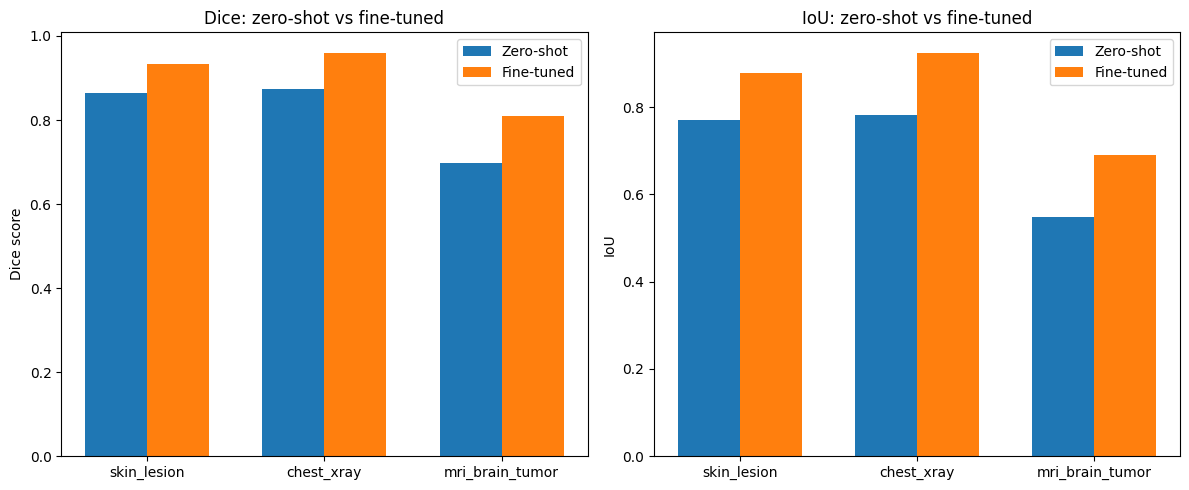

In [21]:
df.to_csv(f"{PROJECT_DIR}/cross_modality_results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(df))
width = 0.35

axes[0].bar(x - width/2, df["zero_shot_dice"], width, label="Zero-shot")
axes[0].bar(x + width/2, df["finetuned_dice"], width, label="Fine-tuned")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df["modality"])
axes[0].set_ylabel("Dice score")
axes[0].set_title("Dice: zero-shot vs fine-tuned")
axes[0].legend()

axes[1].bar(x - width/2, df["zero_shot_iou"], width, label="Zero-shot")
axes[1].bar(x + width/2, df["finetuned_iou"], width, label="Fine-tuned")
axes[1].set_xticks(x)
axes[1].set_xticklabels(df["modality"])
axes[1].set_ylabel("IoU")
axes[1].set_title("IoU: zero-shot vs fine-tuned")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/cross_modality_dice_iou.png", dpi=150)
plt.show()


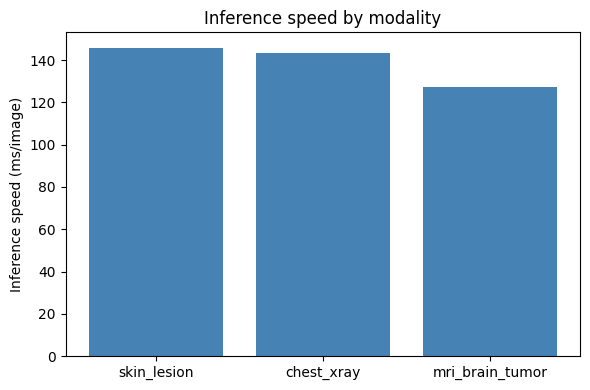

Decoder params are identical across modalities (same architecture, same decoder):
          modality  decoder_params  total_params
0      skin_lesion         4058340      10223204
1       chest_xray         4058340      10223204
2  mri_brain_tumor         4058340      10223204


In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(df["modality"], df["ms_per_image"], color="steelblue")
ax.set_ylabel("Inference speed (ms/image)")
ax.set_title("Inference speed by modality")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/cross_modality_speed.png", dpi=150)
plt.show()

print("Decoder params are identical across modalities (same architecture, same decoder):")
print(df[["modality", "decoder_params", "total_params"]])


### Notes for the writeup

- `cross_modality_results.csv` and the two saved PNGs are ready to drop straight into the
  Part B report / appendix.
- The MRI slicing step keeps only tumor-positive slices and a small patient subset
  (`N_PATIENTS`, `SLICES_PER_PATIENT`) to stay within Colab free-tier limits — say so
  explicitly in the report; it's a scope decision, not an oversight.
- If either Kaggle dataset slug above has moved/been renamed, search the same keywords on
  kaggle.com and swap in whatever slug you find.
- Decoder-param count is expected to be identical across all three modalities (same
  frozen-encoder/light-decoder-tuning setup) — that consistency is what makes the three-way
  comparison apples-to-apples, worth a sentence in the report.


In [23]:
!du -h --max-depth=1 /content | sort -h


148K	/content/.config
2.0M	/content/brats_slices
55M	/content/sample_data
354M	/content/drive
634M	/content/EfficientSAM
20G	/content/chest_xray
45G	/content/brats_raw
65G	/content


In [28]:
!kaggle datasets files -d tschandl/isic2018-challenge-task1-data-segmentation | head -20

Next Page Token = CfDJ8ImuQD4OY2pEnVW2WQ-kgnfqRcssvmJNT5HqmSGf-AkES45ikxa3E7oYoks3FMne_tzxzydlOy96KXDB4BcIrkbXMmPf6Xp-6l6TGtSyx4a6TmaSPM-UXf-ct4dazUbl35lU4gvka5el4ZutMjp4SNVgDlhz1zQal4HK80W62US7UtQ
name                                             size  creationDate                
--------------------------------------------  -------  --------------------------  
ISIC2018_Task1-2_Test_Input/ATTRIBUTION.txt       414  2020-07-14 12:11:21.250000  
ISIC2018_Task1-2_Test_Input/ISIC_0012169.jpg  3337327  2020-07-14 12:11:21.357000  
ISIC2018_Task1-2_Test_Input/ISIC_0012236.jpg  4289420  2020-07-14 12:11:21.455000  
ISIC2018_Task1-2_Test_Input/ISIC_0012292.jpg  2317025  2020-07-14 12:11:21.404000  
ISIC2018_Task1-2_Test_Input/ISIC_0012302.jpg  2763192  2020-07-14 12:11:21.467000  
ISIC2018_Task1-2_Test_Input/ISIC_0012337.jpg  3203959  2020-07-14 12:11:21.545000  
ISIC2018_Task1-2_Test_Input/ISIC_0012373.jpg  4943686  2020-07-14 12:11:21.589000  
ISIC2018_Task1-2_Test_Input/ISIC_0012405.jpg  

In [29]:
# ---------- Skin lesion: pull a couple of sample image+mask pairs directly from Kaggle ----------
SAMPLE_DIR = "/content/skin_samples"
os.makedirs(SAMPLE_DIR, exist_ok=True)

# Replace with real IDs from the Training_Input listing above
sample_ids = ["ISIC_0000123", "ISIC_0000456", "ISIC_0000789"]

for sid in sample_ids:
    !kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation \
        -f "ISIC2018_Task1-2_Training_Input/{sid}.jpg" -p {SAMPLE_DIR} --unzip
    !kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation \
        -f "ISIC2018_Task1_Training_GroundTruth/{sid}_segmentation.png" -p {SAMPLE_DIR} --unzip

img_paths = [f"{SAMPLE_DIR}/{sid}.jpg" for sid in sample_ids]
mask_paths = [f"{SAMPLE_DIR}/{sid}_segmentation.png" for sid in sample_ids]

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 1.37M/1.37M [00:00<00:00, 21.5MB/s]

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 7.83k/7.83k [00:00<00:00, 25.0MB/s]

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 543k/543k [00:00<00:00, 1.48MB/s]

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 19.2k/19.2k [00:00<00:00, 39.9MB/s]

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
404 Client Error: Not Found for url: https://api.kaggle.com/v1/datasets.DatasetApiService/DownloadDataset
Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
404 Client Error: Not Foun

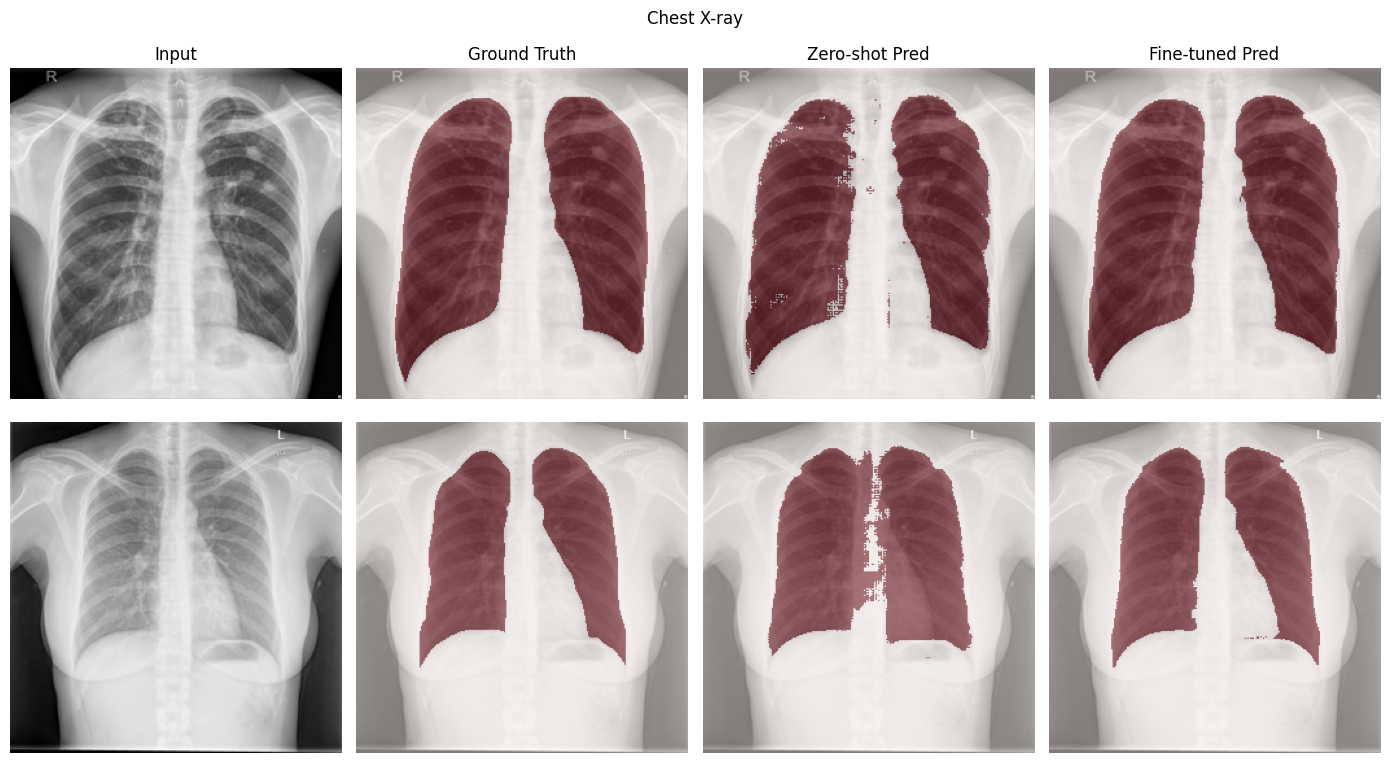

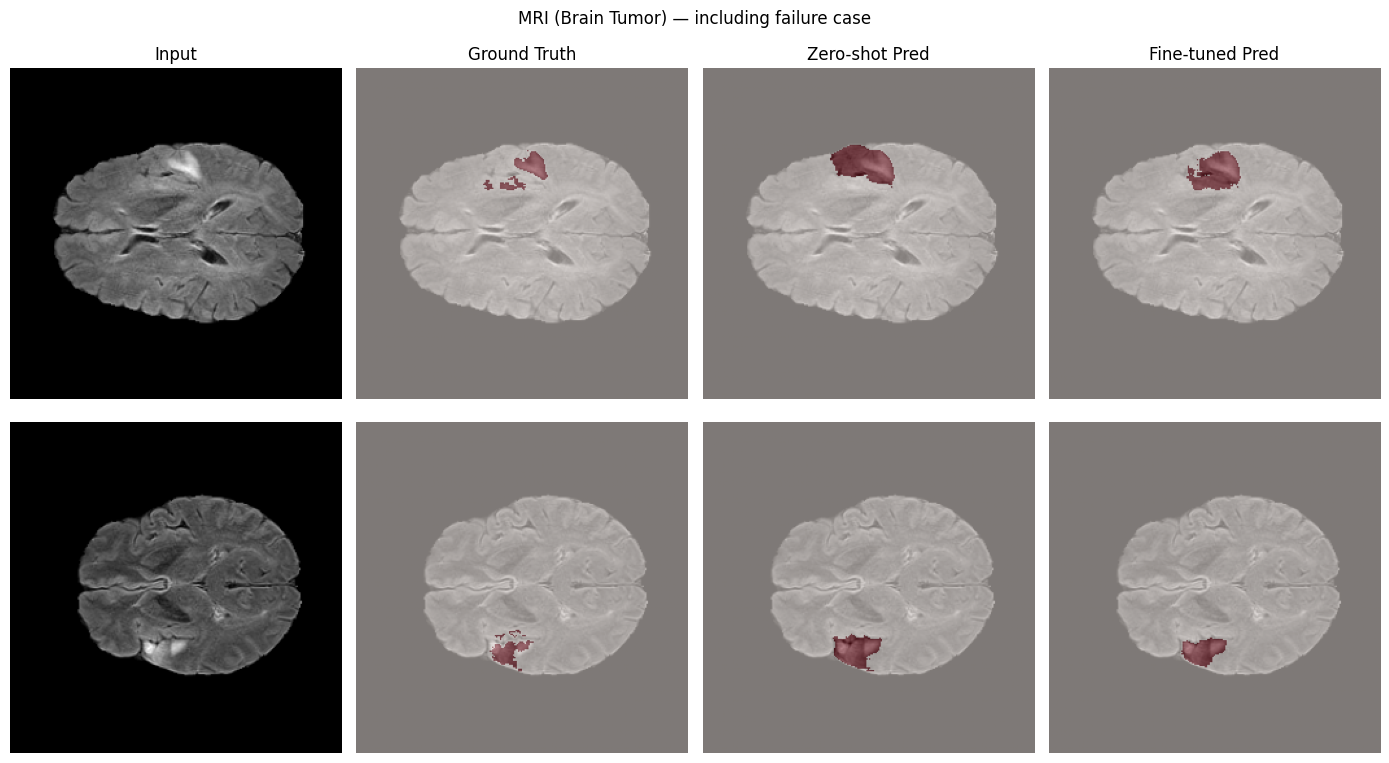

Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
ISIC_0000123.jpg.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
ISIC_0000123_segmentation.png: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
ISIC_0000456.jpg: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
ISIC_0000456_segmentation.png: Skipping, found more recently modified local copy (use --force to force download)


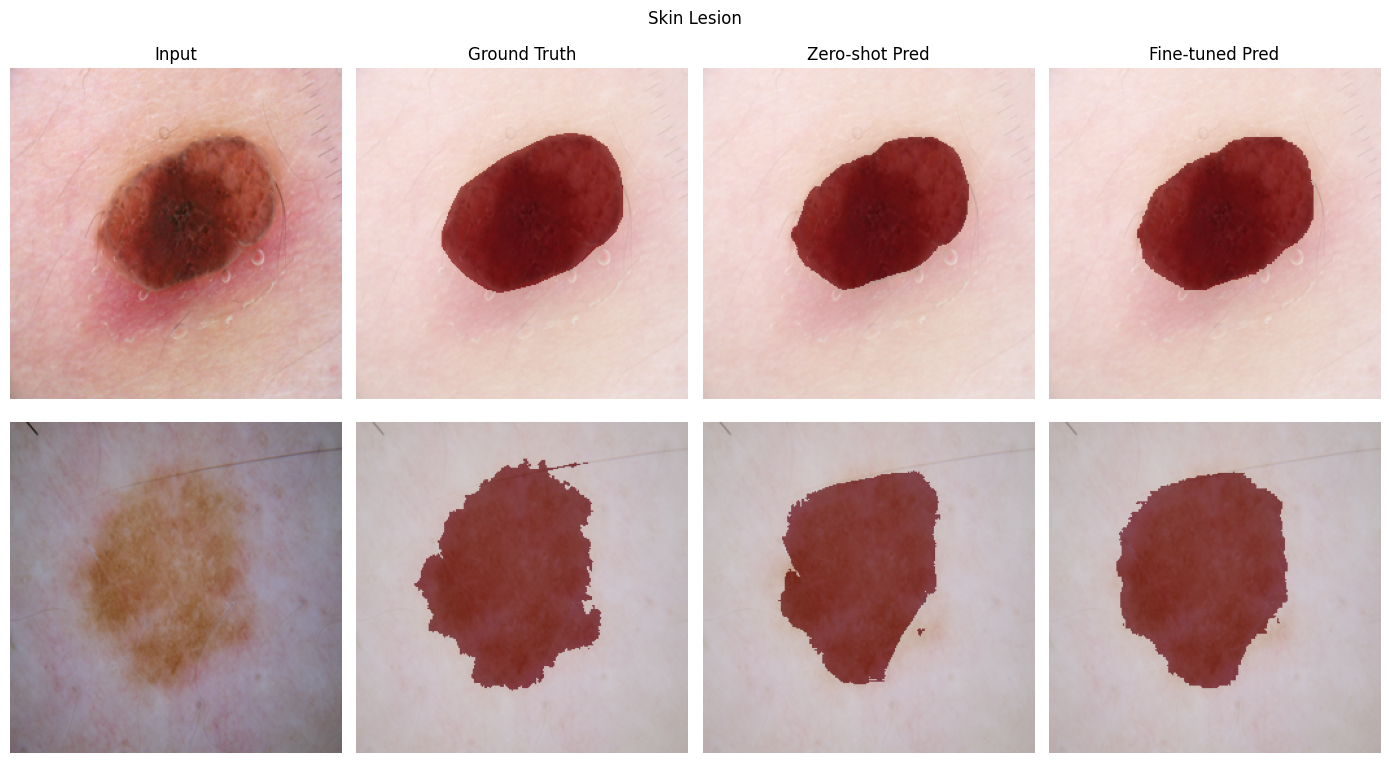

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- Reload skin-lesion models from Drive (dataset itself not needed) ----------
model = build_efficient_sam_vitt().to(device)
model.load_state_dict(torch.load(f"{PROJECT_DIR}/efficientsam_ti_skinlesion_finetuned.pt", map_location=device))
model.eval()

zero_shot_model = build_efficient_sam_vitt().to(device)
zero_shot_model.eval()

# ---------- Chest X-ray and MRI: use your existing val_loaders, no changes needed ----------
show_qualitative_examples("Chest X-ray", xray_zero_shot_model, xray_model, xray_val_loader, device,
                           n_examples=2, save_dir=PROJECT_DIR)

show_qualitative_examples("MRI (Brain Tumor) — including failure case", mri_zero_shot_model, mri_model,
                           mri_val_loader, device, n_examples=2, pick_worst=True, save_dir=PROJECT_DIR)

# ---------- Skin lesion: pull sample image+mask pairs directly from Kaggle (no full download) ----------
SAMPLE_DIR = "/content/skin_samples"
os.makedirs(SAMPLE_DIR, exist_ok=True)

sample_ids = ["ISIC_0000123", "ISIC_0000456"]  # dropped ISIC_0000789 — not a real file  # replace with real IDs you saw above

for sid in sample_ids:
    !kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation \
        -f "ISIC2018_Task1-2_Training_Input/{sid}.jpg" -p {SAMPLE_DIR} --unzip
    !kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation \
        -f "ISIC2018_Task1_Training_GroundTruth/{sid}_segmentation.png" -p {SAMPLE_DIR} --unzip

img_paths = [f"{SAMPLE_DIR}/{sid}.jpg" for sid in sample_ids]
mask_paths = [f"{SAMPLE_DIR}/{sid}_segmentation.png" for sid in sample_ids]

def show_qualitative_examples_from_files(name, zero_shot_model, finetuned_model,
                                          img_paths, mask_paths, device, img_size=256):
    zero_shot_model.eval()
    finetuned_model.eval()

    fig, axes = plt.subplots(len(img_paths), 4, figsize=(14, 4 * len(img_paths)))
    if len(img_paths) == 1:
        axes = axes.reshape(1, -1)
    col_titles = ["Input", "Ground Truth", "Zero-shot Pred", "Fine-tuned Pred"]

    for row, (ip, mp) in enumerate(zip(img_paths, mask_paths)):
        img = Image.open(ip).convert("RGB").resize((img_size, img_size))
        mask = Image.open(mp).convert("L").resize((img_size, img_size), resample=Image.NEAREST)
        img_np = np.array(img)
        mask_t = (transforms.ToTensor()(mask) > 0.5).float()

        ys, xs = torch.where(mask_t[0] > 0)
        if len(xs) == 0:
            box = torch.tensor([[0, 0, img_size - 1, img_size - 1]], dtype=torch.float)
        else:
            box = torch.tensor([[xs.min().item(), ys.min().item(), xs.max().item(), ys.max().item()]], dtype=torch.float)

        img_t = transforms.ToTensor()(img_np).unsqueeze(0).to(device)
        pts, lbls = box_to_prompt(box, device)

        with torch.no_grad():
            zs_logits, _ = zero_shot_model(img_t, pts, lbls)
            ft_logits, _ = finetuned_model(img_t, pts, lbls)

        zs_pred = (zs_logits[0, 0, 0].cpu().numpy() >= 0)
        ft_pred = (ft_logits[0, 0, 0].cpu().numpy() >= 0)
        gt = mask_t[0].numpy().astype(bool)

        panels = [img_np, gt, zs_pred, ft_pred]
        for col, (panel, title) in enumerate(zip(panels, col_titles)):
            ax = axes[row, col]
            ax.imshow(img_np)
            if col > 0:
                ax.imshow(panel, alpha=0.5, cmap="Reds")
            if row == 0:
                ax.set_title(title)
            ax.axis("off")

    fig.suptitle(name)
    plt.tight_layout()
    plt.savefig(f"{PROJECT_DIR}/skin_qualitative.png", dpi=150)
    plt.show()

show_qualitative_examples_from_files("Skin Lesion", zero_shot_model, model, img_paths, mask_paths, device)

In [31]:
import zipfile, glob

# Unzip anything that landed as a .zip instead of being auto-extracted
for zpath in glob.glob(f"{SAMPLE_DIR}/*.zip"):
    with zipfile.ZipFile(zpath, 'r') as zf:
        zf.extractall(SAMPLE_DIR)
    print("Extracted", zpath)

print(os.listdir(SAMPLE_DIR))

# Only keep IDs that actually downloaded successfully
sample_ids = ["ISIC_0000123", "ISIC_0000456"]  # dropped ISIC_0000789 — that ID doesn't exist in the dataset

img_paths = [f"{SAMPLE_DIR}/{sid}.jpg" for sid in sample_ids]
mask_paths = [f"{SAMPLE_DIR}/{sid}_segmentation.png" for sid in sample_ids]

# Sanity check before plotting
for p in img_paths + mask_paths:
    print(p, "exists:", os.path.exists(p))

Extracted /content/skin_samples/ISIC_0000123.jpg.zip
['ISIC_0000123.jpg', 'ISIC_0000456.jpg', 'ISIC_0000456_segmentation.png', 'ISIC_0000123.jpg.zip', 'ISIC_0000123_segmentation.png']
/content/skin_samples/ISIC_0000123.jpg exists: True
/content/skin_samples/ISIC_0000456.jpg exists: True
/content/skin_samples/ISIC_0000123_segmentation.png exists: True
/content/skin_samples/ISIC_0000456_segmentation.png exists: True
